# Carbon & energy flux analysis, by cluster

This notebook compares the fluxes in your dataframe (`C`, `O2`, `photons`, `ac`, `growth`, `n`)
and derives a few carbon/energy-balance metrics, then contrasts everything between the two
clusters in `clusters_4to12h_N_NEW.dat`.

**Variable meaning used below**

- `C` — inorganic carbon fixation (always a source of carbon)
- `O2` — respiration; each unit consumed releases CO2 and yields **5 ATP**
- `photons` — light taken up; each photon yields **0.6 ATP**
- `ac` — organic carbon exchange: **positive = uptake, negative = release**
- `growth` — growth rate
- `n` — the extra variable in your dataframe (included in the generic comparisons below;
  rename/relabel it if it means something specific, e.g. nitrogen uptake)

Edit the file paths in the "Load data" cell to point at your actual files, then run all cells.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

# --- Palette -----------------------------------------------------------
# Fixed, colorblind-safe categorical order (never re-cycled), a sequential
# single-hue ramp for magnitude, and a diverging blue<->red pair with a
# neutral midpoint for signed quantities (e.g. correlations, ac).
CAT = {
    'blue':   '#2a78d6',
    'red':    '#e34948',
    'orange': '#eb6834',
    'aqua':   '#1baf7a',
    'yellow': '#eda100',
    'violet': '#4a3aa7',

}
CLUSTER_COLORS = {0: CAT['blue'], 1: CAT['red']}   # extend if you ever have >2 clusters
SOURCE_COLORS  = {'fixation': CAT['aqua'], 'organic': CAT['yellow']}
SEQ_CMAP = sns.light_palette(CAT['blue'], as_cmap=True)
DIV_CMAP = plt.cm.coolwarm
#sns.diverging_palette(220, 10, s=75, l=50, sep=10, as_cmap=True)

INK, MUTED, GRID, SURFACE = '#0b0b0b', '#898781', '#e1e0d9', '#fcfcfb'

sns.set_theme(style='white', font='sans-serif')
mpl.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'text.color': INK,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'grid.color': GRID,
    'axes.grid': True, 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 11, 'figure.dpi': 110,
})

RAW_VARS = ['C', 'O2', 'photons', 'ac', 'growth', 'n']

## Load data

Point `df` at your fluxes dataframe (however you currently build/load it) and merge in the
cluster labels. The merge below assumes both files share the same row order/length — swap in
an index- or id-based merge if that's not the case for you.

In [3]:
# --- EDIT THIS: however you currently load your fluxes dataframe ---
df =  pd.read_csv('results_new/results_std_corrected_12_toy_model_avg_PEAKS_ox.dat', sep='\t')   # <-- replace with your actual source
# ---------------------------------------------------------------------

clusters = pd.read_csv('results_new/clusters_4to12h_N_NEW.dat', sep='\t')

assert len(df) == len(clusters), (
    f"df has {len(df)} rows but clusters has {len(clusters)} rows — "
    "align them (e.g. merge on a shared id/index) before continuing."
)
df = df.reset_index(drop=True)
df['cluster'] = clusters['cluster'].values

df.head()

,C,O2,photons,ac,growth,n,cluster
0,1.948179,0.041683,22.987729,0.580263,0.060653,0.826900,1
1,2.227050,0.588670,21.975861,0.667831,0.056249,0.926153,1
2,2.532237,1.015061,20.239184,-1.113878,0.009837,0.425351,0
3,2.606429,1.328259,19.465911,-0.766908,0.012470,0.468042,0
4,2.810133,1.328891,20.437260,-0.954352,0.012851,0.453945,0


## Derived carbon & energy metrics

- **ATP supply**: `ATP_respiration = 5 * O2`, `ATP_photon = 0.6 * photons`, `ATP_total` = their sum
- **Carbon retained from fixation**: `C_fixation_net = C - O2` (fixed carbon net of what respiration
  burns back off as CO2); clipped at 0 when respiration outweighs fixation
- **Organic carbon uptake / release**: the positive / negative part of `ac`
- **Carbon reaching biomass**: `C_to_biomass = max(C_fixation_net, 0) + C_organic_uptake`, split into
  `frac_from_fixation` and `frac_from_organic`
- **Carbon yield**: `growth / (C + C_organic_uptake)` — biomass produced per unit carbon taken up
- **Energy yield**: `growth / ATP_total` — biomass produced per unit ATP generated

In [4]:
df['ATP_respiration'] = 5.0 * df['O2']
df['ATP_photon']      = 0.6 * df['photons']
df['ATP_total']       = df['ATP_respiration'] + df['ATP_photon']

df['C_fixation_net']    = df['C'] - df['O2']
df['C_organic_uptake']  = df['ac'].clip(lower=0)
df['C_organic_release'] = (-df['ac']).clip(lower=0)

df['C_to_biomass']       = df['C_fixation_net'].clip(lower=0) + df['C_organic_uptake']
df['frac_from_fixation'] = df['C_fixation_net'].clip(lower=0) / df['C_to_biomass']
df['frac_from_organic']  = df['C_organic_uptake']            / df['C_to_biomass']
df[['frac_from_fixation', 'frac_from_organic']] = (
    df[['frac_from_fixation', 'frac_from_organic']].replace([np.inf, -np.inf], np.nan)
)

df['C_uptake_total'] = df['C'] + df['C_organic_uptake']
df['carbon_yield']   = df['growth'] / df['C_uptake_total']
df['energy_yield']   = df['growth'] / df['ATP_total']

DERIVED_VARS = ['ATP_total', 'carbon_yield', 'energy_yield', 'frac_from_fixation', 'frac_from_organic']
df[DERIVED_VARS].describe()

,ATP_total,carbon_yield,energy_yield,frac_from_fixation,frac_from_organic
count,520.000000,520.000000,5.200000e+02,520.000000,520.000000
mean,18.128250,0.008392,1.559043e-03,0.783961,0.216039
std,1.230859,0.007276,1.428648e-03,0.255455,0.255455
min,14.001053,0.000001,2.264709e-07,0.269255,0.000000
25%,17.355830,0.000042,6.118009e-06,0.527443,0.000000
50%,18.062325,0.009233,1.310222e-03,1.000000,0.000000
75%,18.885235,0.015477,3.048243e-03,1.000000,0.472557
max,24.522195,0.023988,4.332008e-03,1.000000,0.730745


In [5]:
df

,C,O2,photons,ac,growth,n,cluster,ATP_respiration,ATP_photon,ATP_total,C_fixation_net,C_organic_uptake,C_organic_release,C_to_biomass,frac_from_fixation,frac_from_organic,C_uptake_total,carbon_yield,energy_yield
0,1.948179,0.041683,22.987729,0.580263,0.060653,0.826900,1,0.208415,13.792638,14.001053,1.906496,0.580263,0.000000,2.486759,0.766659,0.233341,2.528442,0.023988,4.332008e-03
1,2.227050,0.588670,21.975861,0.667831,0.056249,0.926153,1,2.943348,13.185517,16.128865,1.638380,0.667831,0.000000,2.306211,0.710421,0.289579,2.894880,0.019431,3.487477e-03
2,2.532237,1.015061,20.239184,-1.113878,0.009837,0.425351,0,5.075304,12.143510,17.218814,1.517176,0.000000,1.113878,1.517176,1.000000,0.000000,2.532237,0.003885,5.712679e-04
3,2.606429,1.328259,19.465911,-0.766908,0.012470,0.468042,0,6.641296,11.679546,18.320843,1.278170,0.000000,0.766908,1.278170,1.000000,0.000000,2.606429,0.004784,6.806345e-04
4,2.810133,1.328891,20.437260,-0.954352,0.012851,0.453945,0,6.644457,12.262356,18.906813,1.481241,0.000000,0.954352,1.481241,1.000000,0.000000,2.810133,0.004573,6.796997e-04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
515,2.516049,0.967061,20.167429,-1.381136,0.004094,0.570559,0,4.835305,12.100457,16.935762,1.548988,0.000000,1.381136,1.548988,1.000000,0.000000,2.516049,0.001627,2.417342e-04
516,2.441441,1.062329,19.334759,-1.378906,0.000005,0.269305,0,5.311647,11.600855,16.912502,1.379111,0.000000,1.378906,1.379111,1.000000,0.000000,2.441441,0.000002,2.958638e-07
517,2.547117,1.129764,21.216184,0.787810,0.053784,1.039095,1,5.648818,12.729710,18.378528,1.417353,0.787810,0.000000,2.205163,0.642743,0.357257,3.334927,0.016128,2.926484e-03
518,2.742121,1.197904,20.187125,-1.544012,0.000005,0.364886,0,5.989518,12.112275,18.101793,1.544217,0.000000,1.544012,1.544217,1.000000,0.000000,2.742121,0.000002,2.764256e-07


## 1. Correlation between the raw fluxes

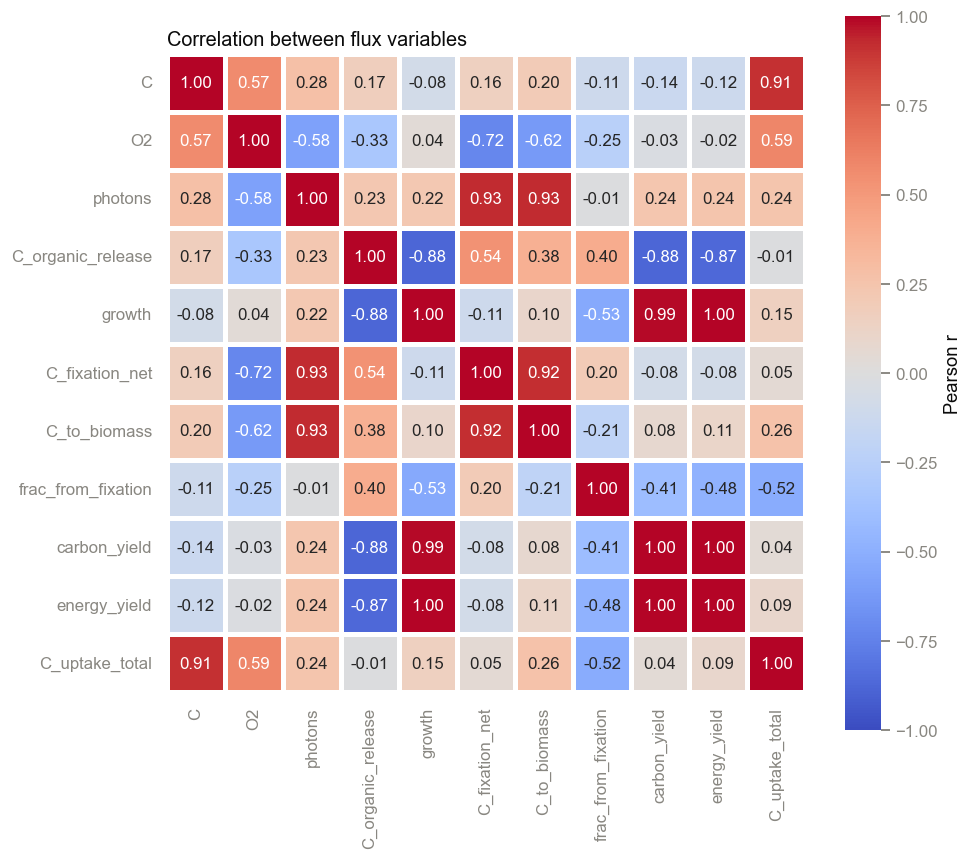

In [6]:
variables = ['C', 'O2', 'photons', 'C_organic_release', 'growth', 'C_fixation_net',
             'C_to_biomass', 'frac_from_fixation', 'carbon_yield', 'energy_yield', 'C_uptake_total']

corr = df[df['cluster'] == 0][variables].corr()

fig, ax = plt.subplots(figsize=(9, 8), facecolor='white')
ax.set_facecolor('white')

sns.heatmap(corr, cmap=DIV_CMAP, vmin=-1, vmax=1, center=0, annot=True, fmt='.2f',
            square=True, linewidths=2, linecolor='white',
            cbar_kws={'label': 'Pearson r'}, ax=ax)

ax.set_title('Correlation between flux variables', loc='left', fontsize=13, color=INK)
plt.tight_layout()
plt.savefig('fig1_corr_heatmap.png', dpi=150, facecolor='white', bbox_inches='tight')
plt.show()

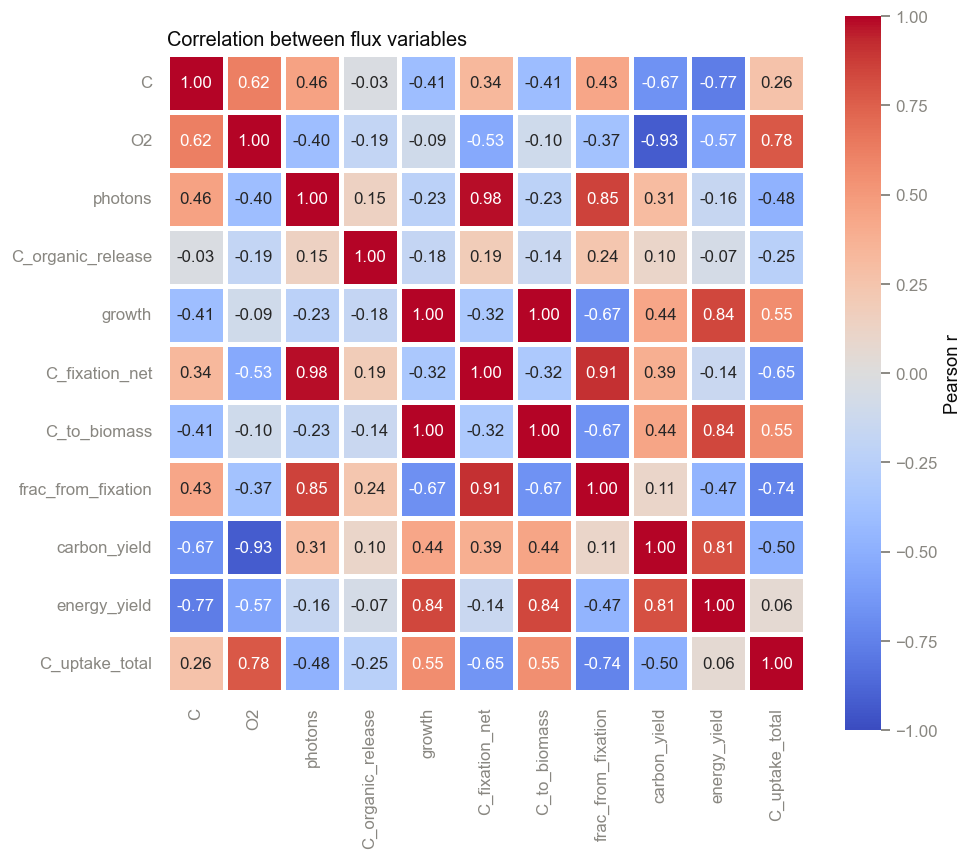

In [9]:
variables = ['C', 'O2', 'photons', 'C_organic_release', 'growth', 'C_fixation_net',
             'C_to_biomass', 'frac_from_fixation', 'carbon_yield', 'energy_yield', 'C_uptake_total']

corr = df[df['cluster'] == 1][variables].corr()

fig, ax = plt.subplots(figsize=(9, 8), facecolor='white')
ax.set_facecolor('white')

sns.heatmap(corr, cmap=DIV_CMAP, vmin=-1, vmax=1, center=0, annot=True, fmt='.2f',
            square=True, linewidths=2, linecolor='white',
            cbar_kws={'label': 'Pearson r'}, ax=ax)

ax.set_title('Correlation between flux variables', loc='left', fontsize=13, color=INK)
plt.tight_layout()
plt.savefig('fig2_corr_heatmap.png', dpi=150, facecolor='white', bbox_inches='tight')
plt.show()

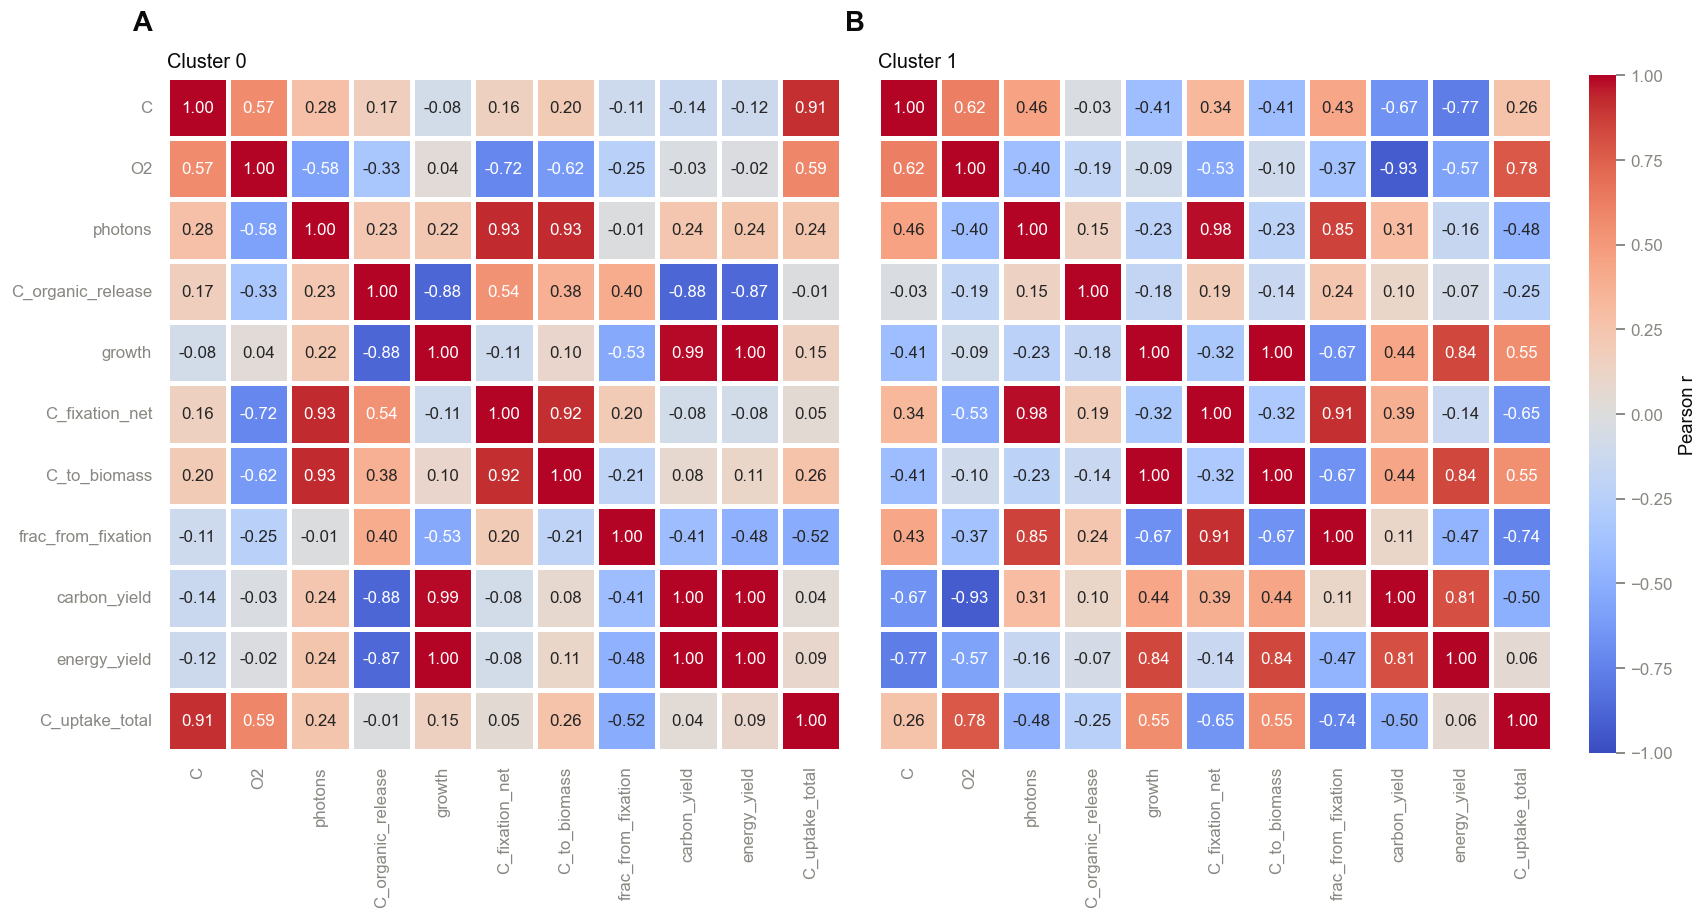

In [10]:
variables = ['C', 'O2', 'photons', 'C_organic_release', 'growth', 'C_fixation_net',
             'C_to_biomass', 'frac_from_fixation', 'carbon_yield', 'energy_yield', 'C_uptake_total']

corr0 = df[df['cluster'] == 0][variables].corr()
corr1 = df[df['cluster'] == 1][variables].corr()

fig = plt.figure(figsize=(17, 8), facecolor='white')
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.04], wspace=0.08)
axA = fig.add_subplot(gs[0])
axB = fig.add_subplot(gs[1])
cax = fig.add_subplot(gs[2])

common = dict(cmap=DIV_CMAP, vmin=-1, vmax=1, center=0, annot=True, fmt='.2f',
              square=True, linewidths=2, linecolor='white')

sns.heatmap(corr0, ax=axA, cbar=False, **common)
sns.heatmap(corr1, ax=axB, cbar_ax=cax, cbar_kws={'label': 'Pearson r'},
            yticklabels=False, **common)

for ax, label, title in [(axA, 'A', 'Cluster 0'), (axB, 'B', 'Cluster 1')]:
    ax.set_facecolor('white')
    ax.set_title(title, loc='left', fontsize=13, color=INK)
    ax.text(-0.02, 1.06, label, transform=ax.transAxes,
            fontsize=18, fontweight='bold', color=INK, ha='right', va='bottom')

plt.savefig('fig1_corr_heatmap_clusters.png', dpi=300, facecolor='white', bbox_inches='tight')
plt.show()

## 2. Pairwise relationships, colored by cluster

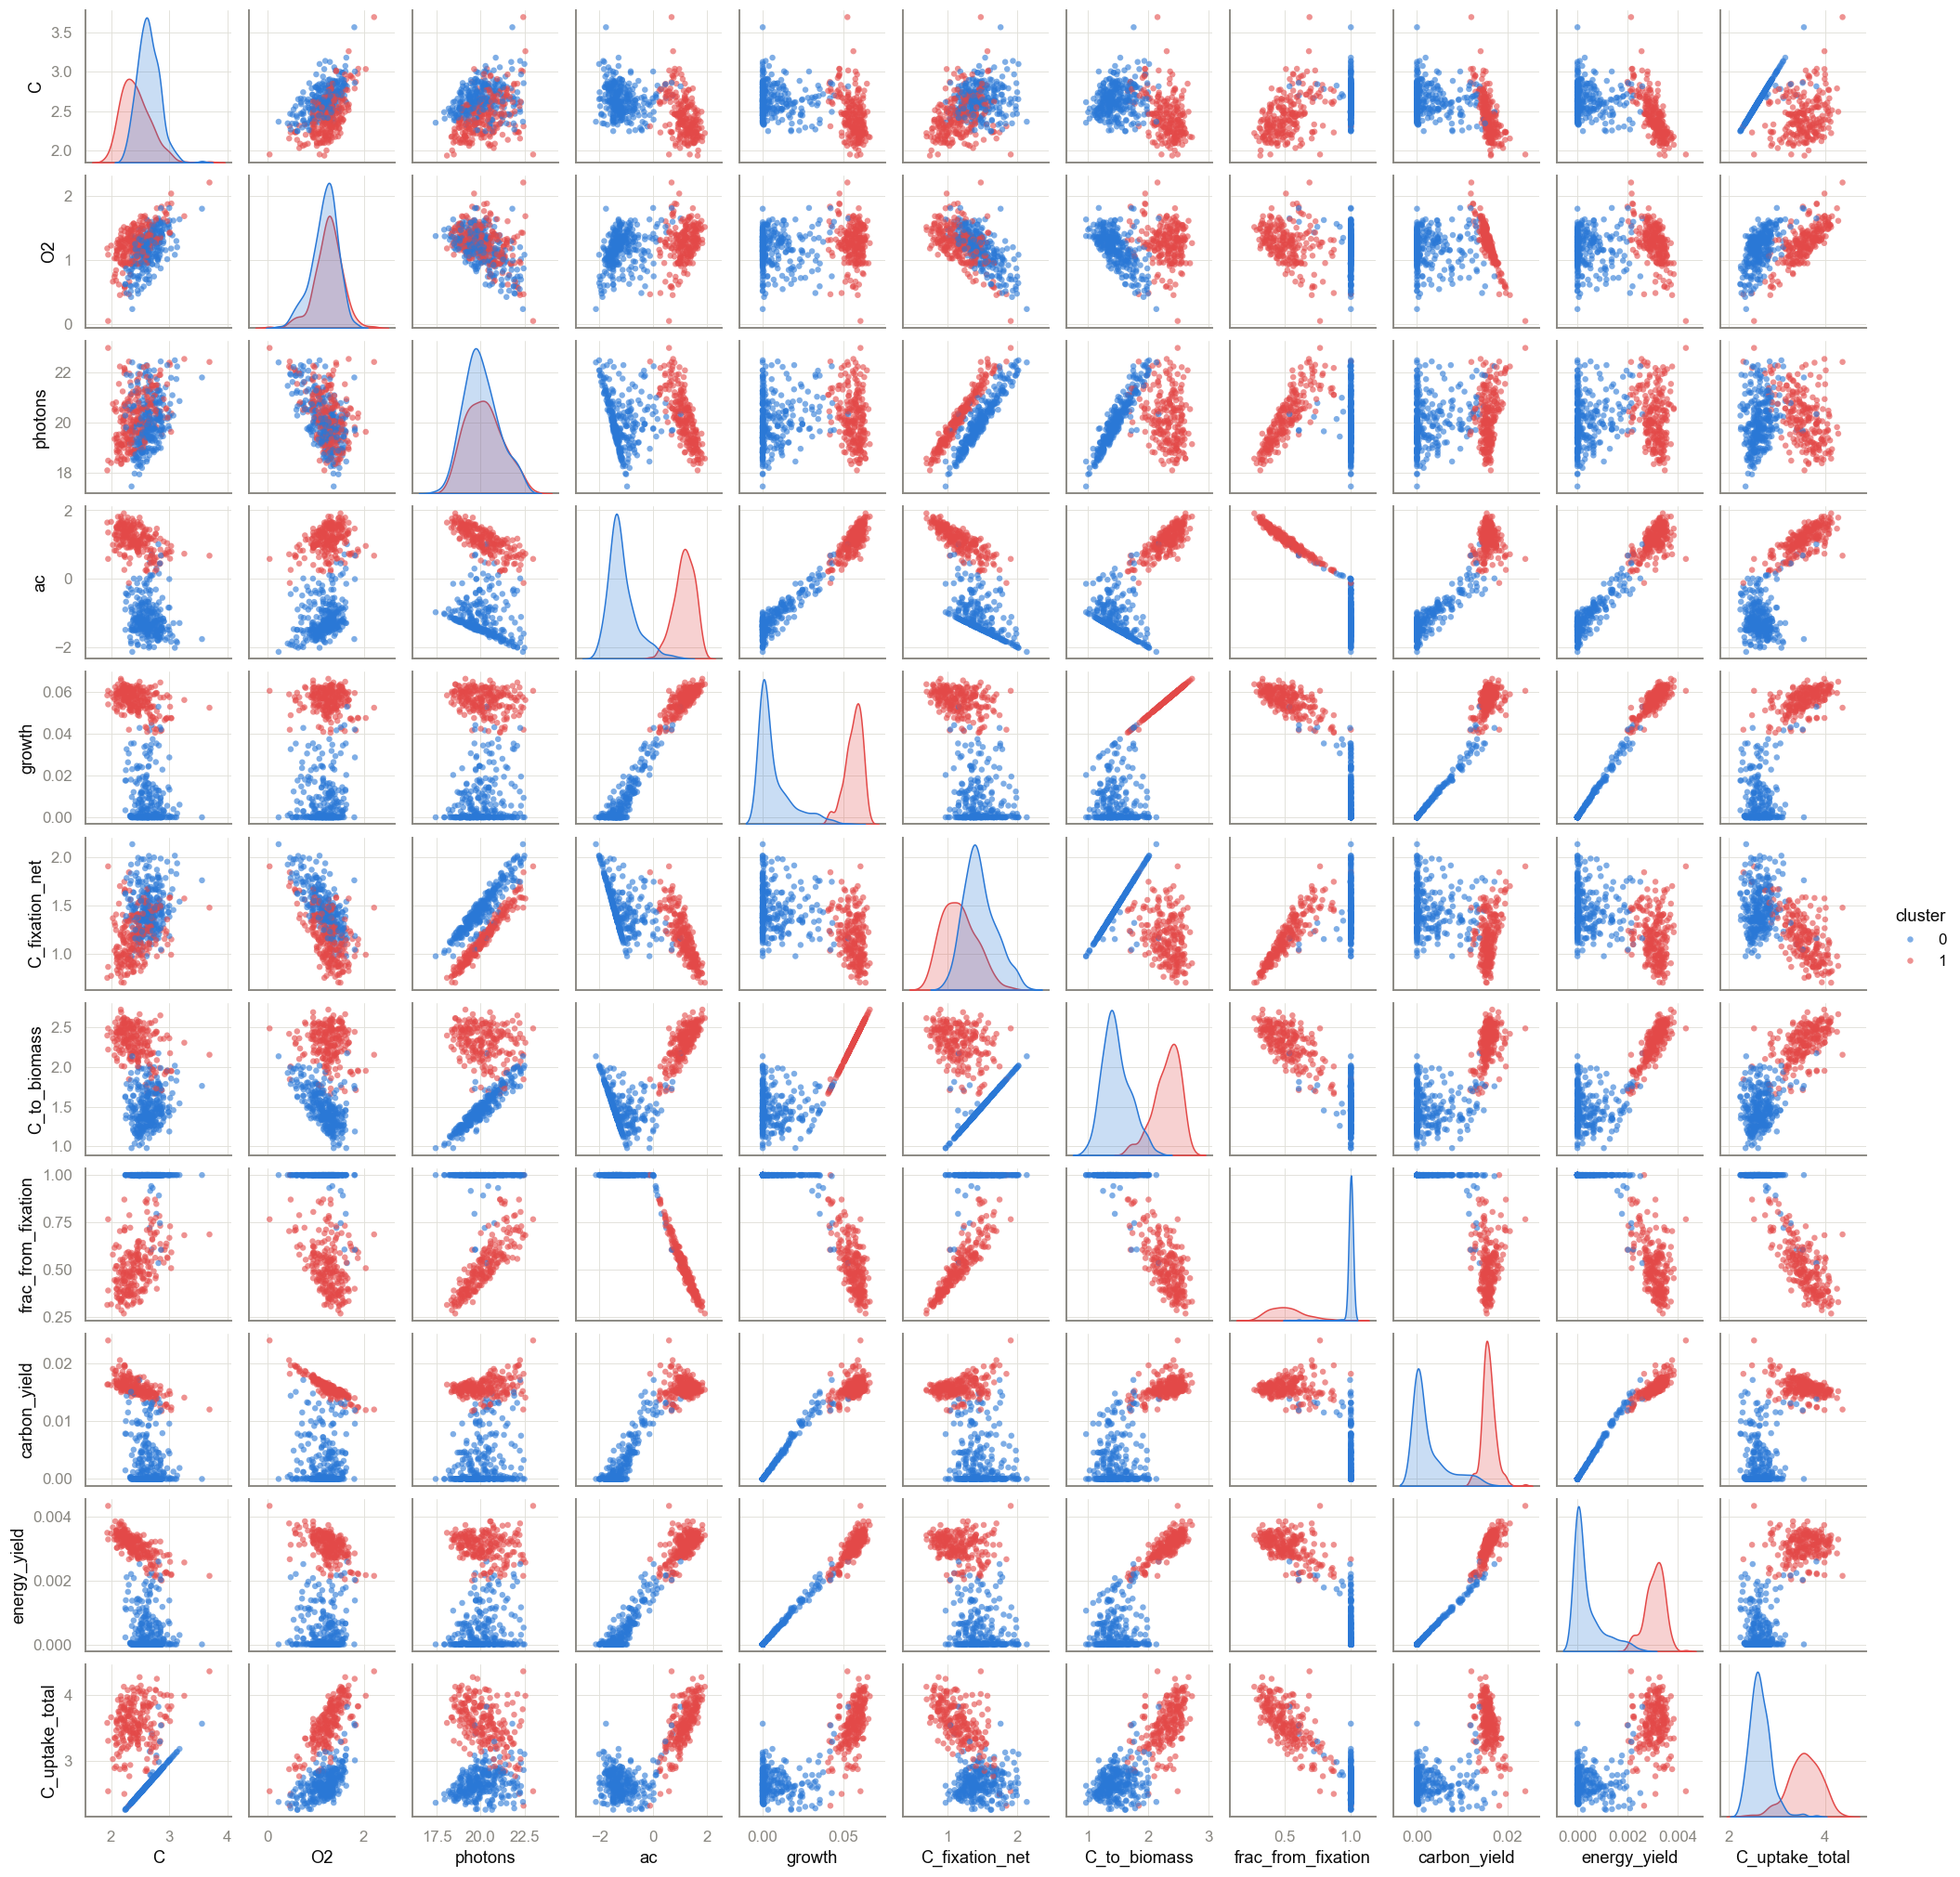

In [14]:
variables = ['C', 'O2', 'photons', 'ac', 'growth', 'C_fixation_net',
             'C_to_biomass', 'frac_from_fixation', 'carbon_yield', 'energy_yield', 'C_uptake_total']

g = sns.pairplot(df, vars=variables, hue='cluster', palette=CLUSTER_COLORS,
                 diag_kind='kde', plot_kws=dict(s=18, alpha=0.6, linewidth=0),
                 height=1.7)

g.fig.set_facecolor('white')
for ax in g.axes.flat:
    if ax is not None:
        ax.set_facecolor('white')

#g.fig.suptitle('Pairwise relationships between flux variables, by cluster', y=1.02)
g._legend.set_title('cluster')

plt.savefig('fig2_pairplot.png', dpi=130, bbox_inches='tight', facecolor='white')
plt.show()

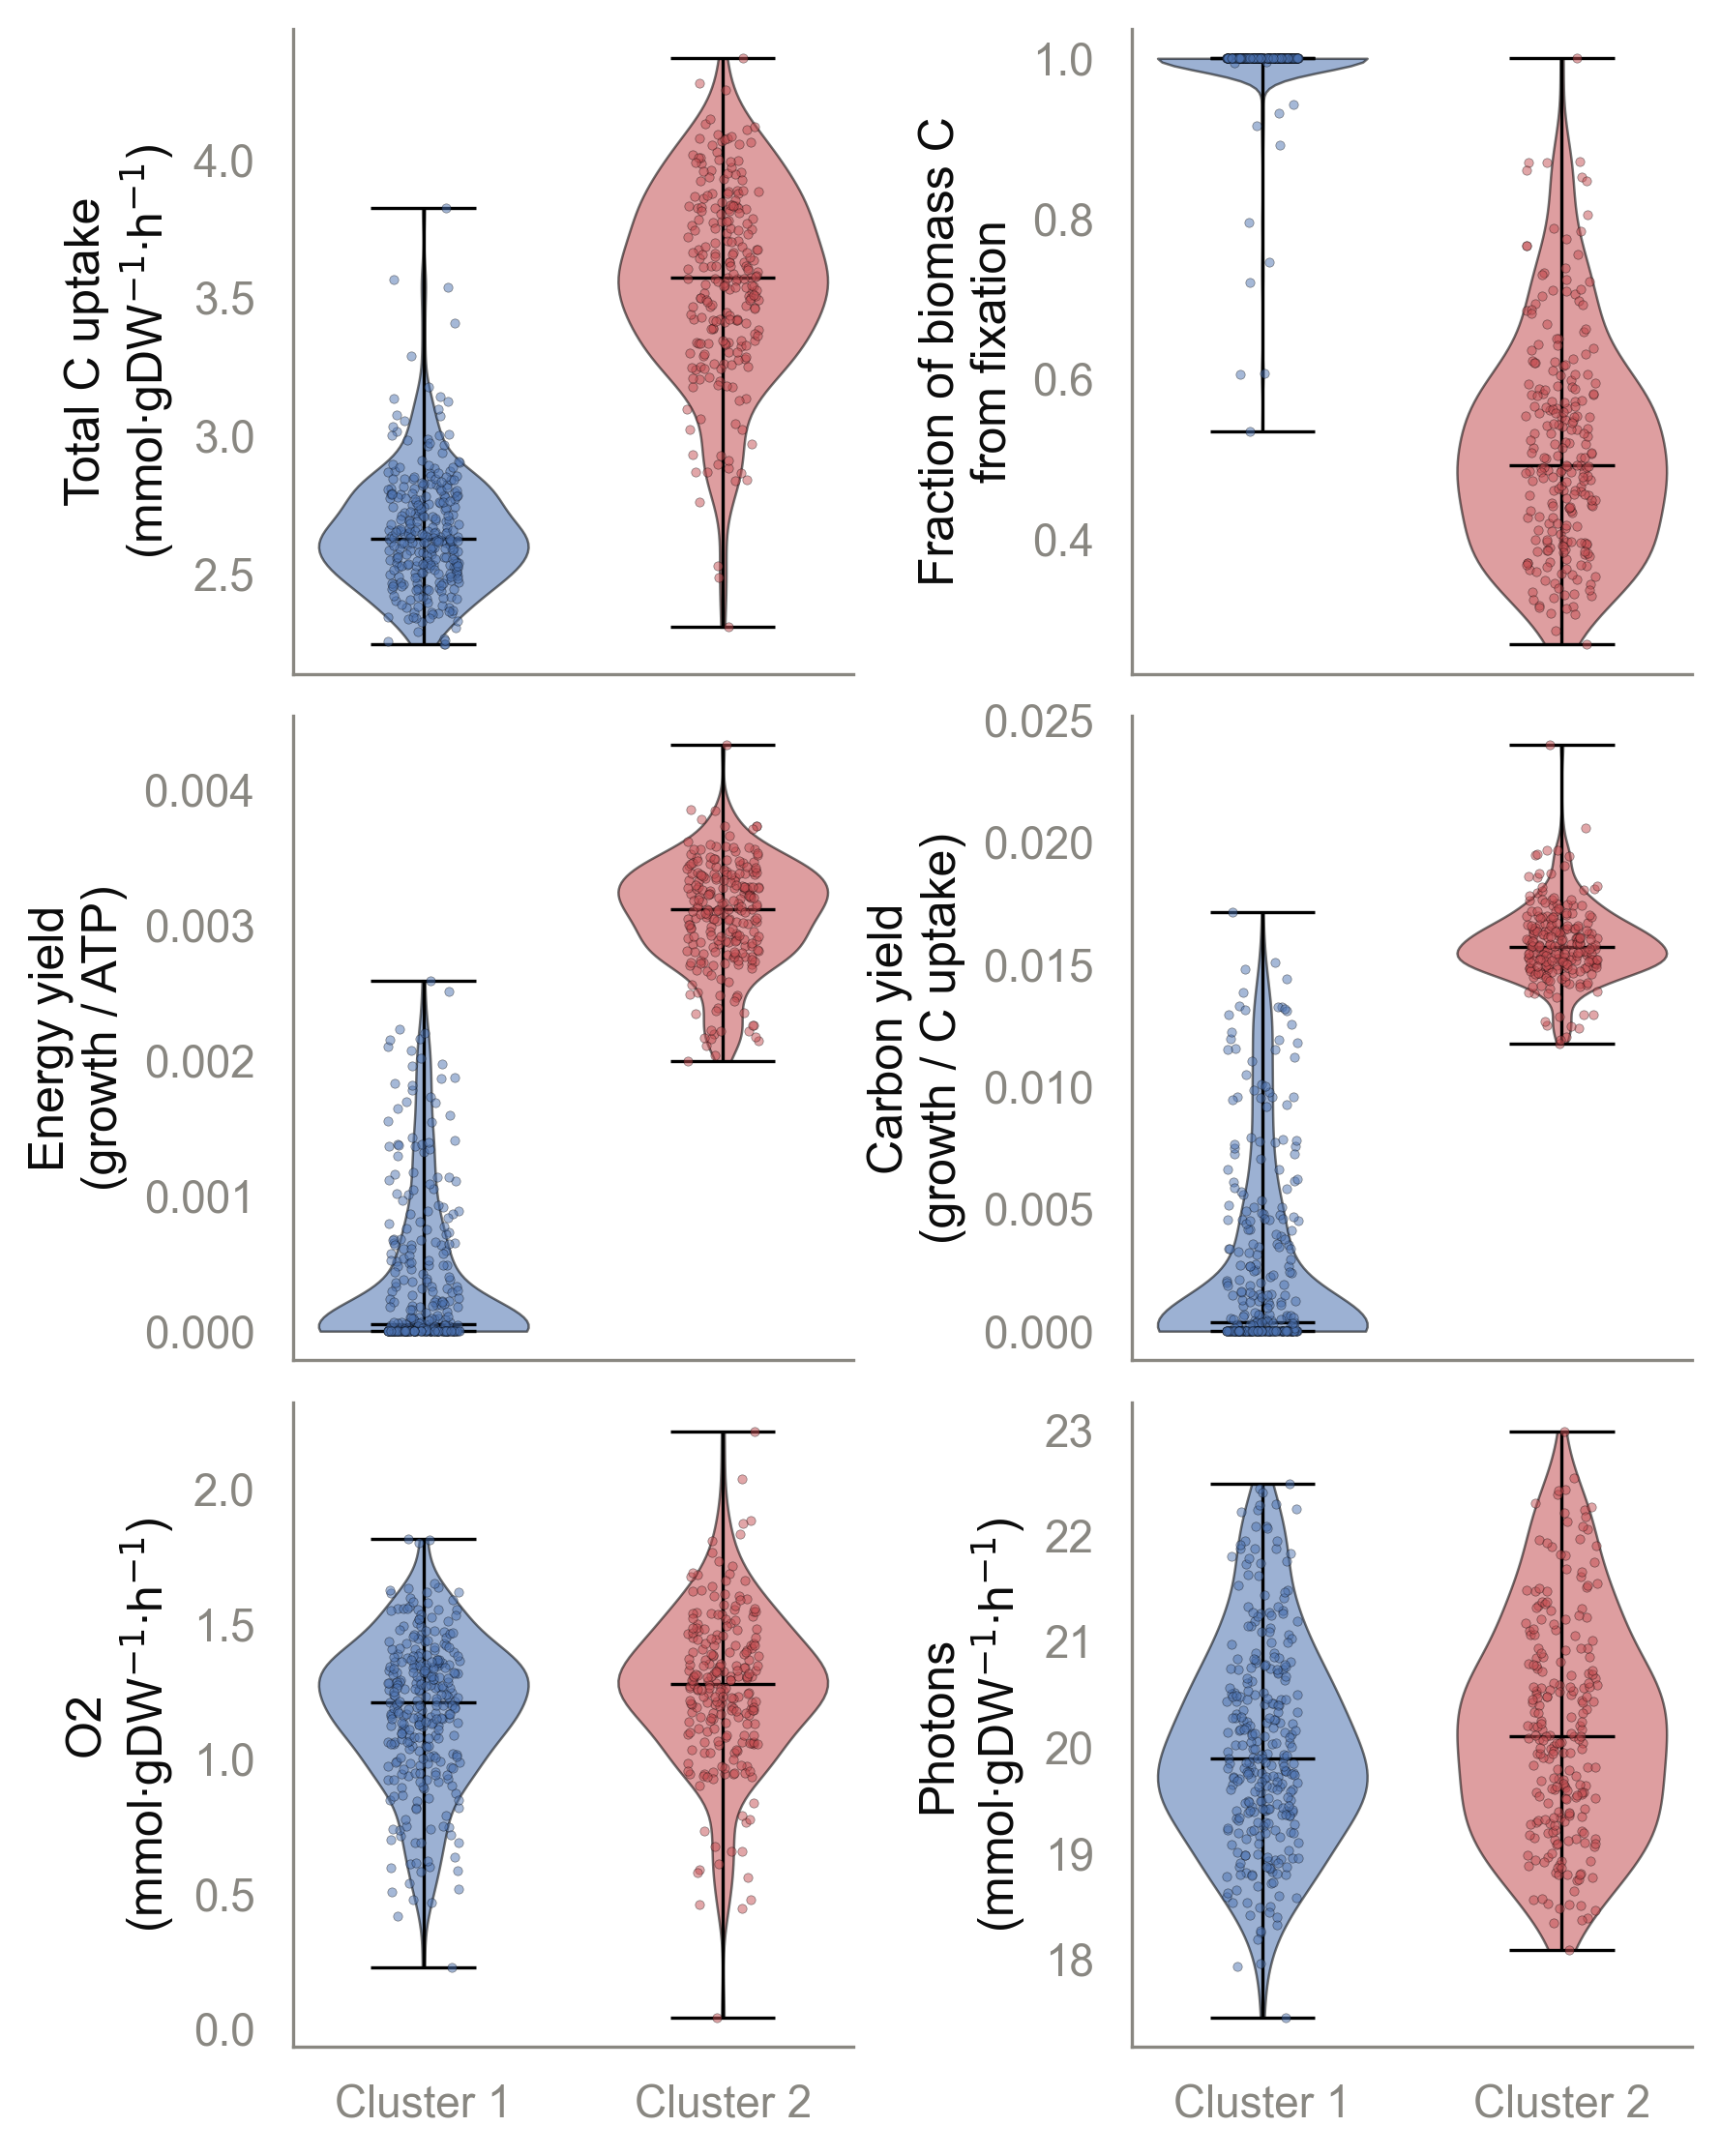

In [53]:
CLUSTER_COLORS = {0: '#4C72B0', 1: '#C44E52'}

plt.rcParams.update({
    'font.family': 'sans-serif', 'font.size': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.linewidth': 0.8, 'xtick.major.width': 0.8, 'ytick.major.width': 0.8,
    'axes.facecolor': 'white', 'figure.facecolor': 'white', 'axes.grid': False,
})

panels = [
    ('C_uptake_total',     'Total C uptake\n(mmol·gDW$^{-1}$·h$^{-1}$)'),
    ('frac_from_fixation', 'Fraction of biomass C\nfrom fixation'),
    ('energy_yield',       'Energy yield\n(growth / ATP)'),
    ('carbon_yield',       'Carbon yield\n(growth / C uptake)'),
    ('O2',                 'O2\n(mmol·gDW$^{-1}$·h$^{-1}$)'),
    ('photons',            'Photons\n(mmol·gDW$^{-1}$·h$^{-1}$)'),
]

rng = np.random.default_rng(0)

fig, axes = plt.subplots(3, 2, figsize=(6, 7.5), dpi=300, sharex=True)
for ax, (var, ylabel) in zip(axes.flat, panels):
    data = [df.loc[df.cluster == cl, var].dropna().values for cl in [0, 1]]

    parts = ax.violinplot(data, showmedians=True, widths=0.7)
    for pc, cl in zip(parts['bodies'], [0, 1]):
        pc.set_facecolor(CLUSTER_COLORS[cl]); pc.set_edgecolor('black')
        pc.set_alpha(0.55); pc.set_linewidth(0.6); pc.set_zorder(1)
    for part_name in ['cmedians', 'cbars', 'cmins', 'cmaxes']:
        parts[part_name].set_color('black'); parts[part_name].set_linewidth(0.8)
        parts[part_name].set_zorder(2)

    for i, cl in enumerate([0, 1], start=1):
        vals = data[i - 1]
        xs = i + rng.uniform(-0.12, 0.12, size=len(vals))
        ax.scatter(xs, vals, s=5, color=CLUSTER_COLORS[cl], edgecolor='black',
                   linewidth=0.15, alpha=0.5, zorder=3)

    ax.set_facecolor('white')
    ax.grid(False)
    ax.set_xticks([1, 2])
    ax.set_ylabel(ylabel)

for ax in axes[-1, :]:
    ax.set_xticklabels(['Cluster 1', 'Cluster 2'])
for ax in axes[:-1, :].flat:
    ax.tick_params(labelbottom=False)

fig.tight_layout()
fig.savefig('violin_grid_3x2.png', transparent=False, format='png')
plt.show()

## 3. Each raw variable's distribution, by cluster

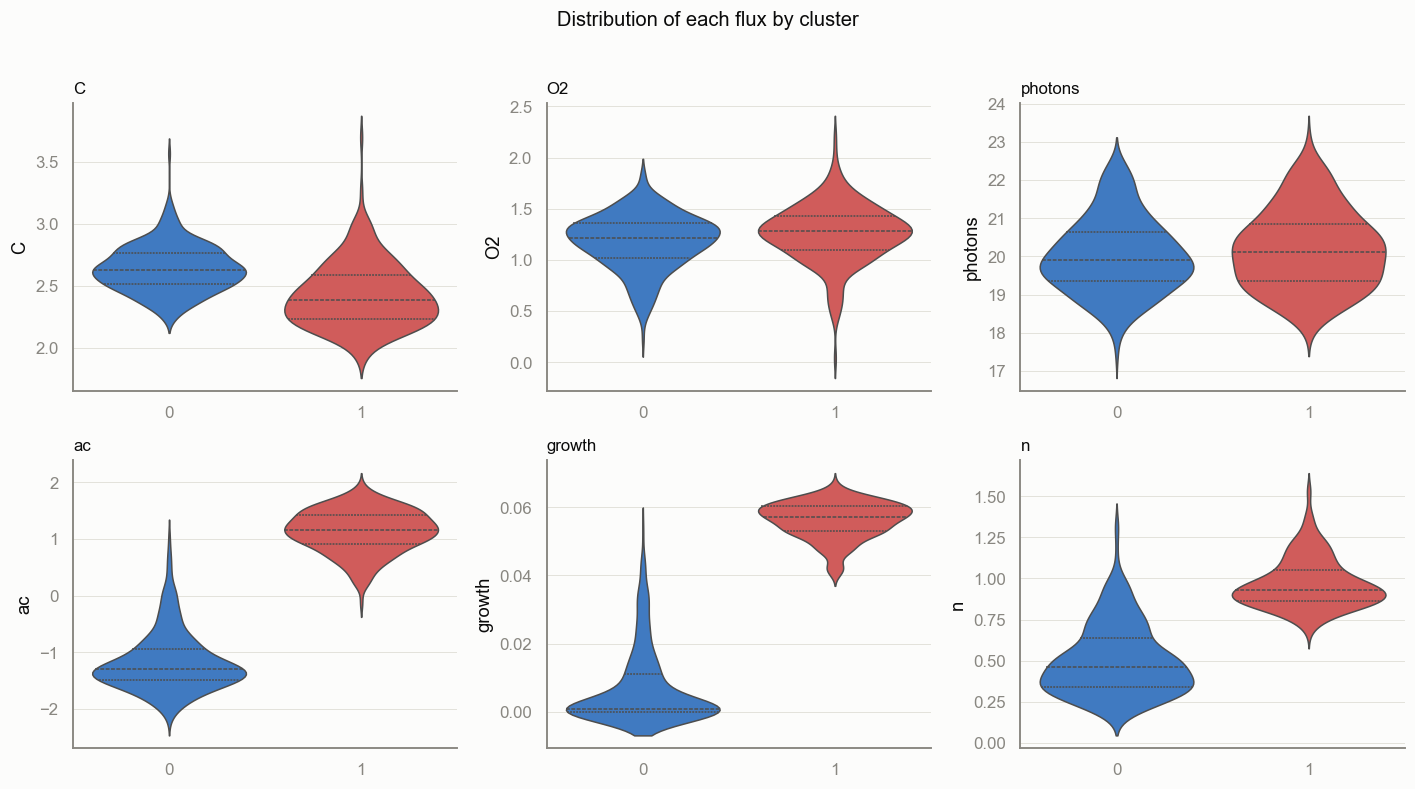

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, var in zip(axes.flat, RAW_VARS):
    sns.violinplot(data=df, x='cluster', y=var, hue='cluster', palette=CLUSTER_COLORS,
                    legend=False, inner='quartile', ax=ax, linewidth=1)
    ax.set_title(var, loc='left', fontsize=11)
    ax.set_xlabel('')
fig.suptitle('Distribution of each flux by cluster', y=1.02)
plt.tight_layout()
plt.savefig('fig3_raw_dist_by_cluster.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Derived carbon/energy metrics, by cluster

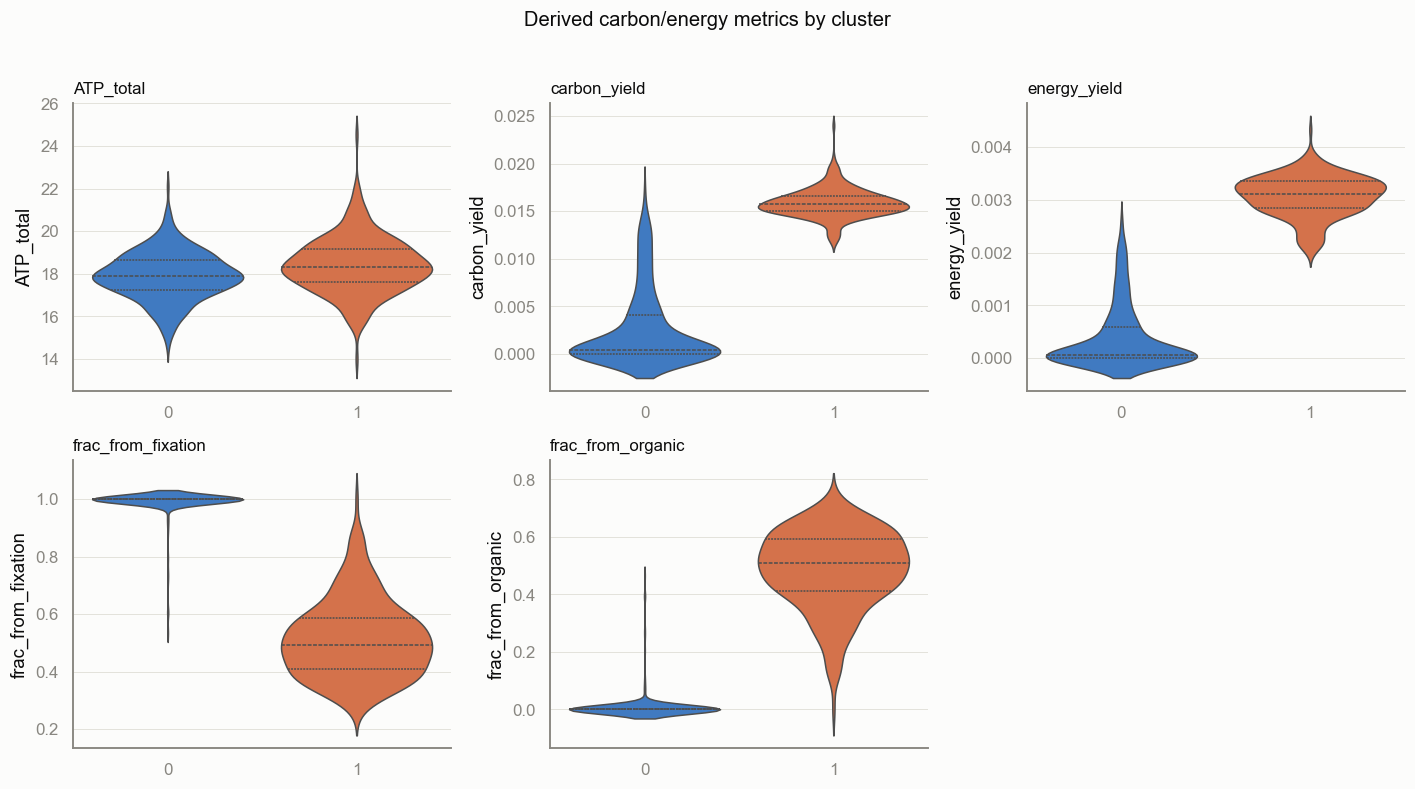

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, var in zip(axes.flat, DERIVED_VARS):
    sns.violinplot(data=df, x='cluster', y=var, hue='cluster', palette=CLUSTER_COLORS,
                    legend=False, inner='quartile', ax=ax, linewidth=1)
    ax.set_title(var, loc='left', fontsize=11)
    ax.set_xlabel('')
axes.flat[-1].axis('off')
fig.suptitle('Derived carbon/energy metrics by cluster', y=1.02)
plt.tight_layout()
plt.savefig('fig4_derived_dist_by_cluster.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Where does biomass carbon come from?\n\nMean share of the carbon reaching biomass that comes from CO2 fixation vs. organic-carbon uptake, per cluster.

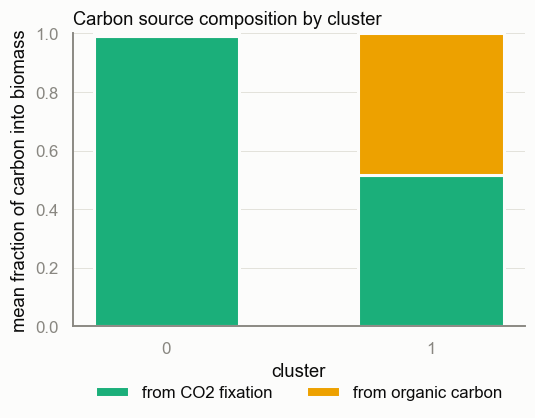

In [8]:
comp = df.groupby('cluster')[['frac_from_fixation', 'frac_from_organic']].mean()

fig, ax = plt.subplots(figsize=(5, 4))
bottom = np.zeros(len(comp))
for col, label, color in [('frac_from_fixation', 'from CO2 fixation', SOURCE_COLORS['fixation']),
                           ('frac_from_organic',  'from organic carbon', SOURCE_COLORS['organic'])]:
    ax.bar(comp.index.astype(str), comp[col], bottom=bottom, label=label, color=color,
           edgecolor=SURFACE, linewidth=2, width=0.55)
    bottom += comp[col].values
ax.set_ylabel('mean fraction of carbon into biomass')
ax.set_xlabel('cluster')
ax.set_ylim(0, 1)
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)
ax.set_title('Carbon source composition by cluster', loc='left')
plt.tight_layout()
plt.savefig('fig5_carbon_source_stacked.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Growth rate vs. efficiency

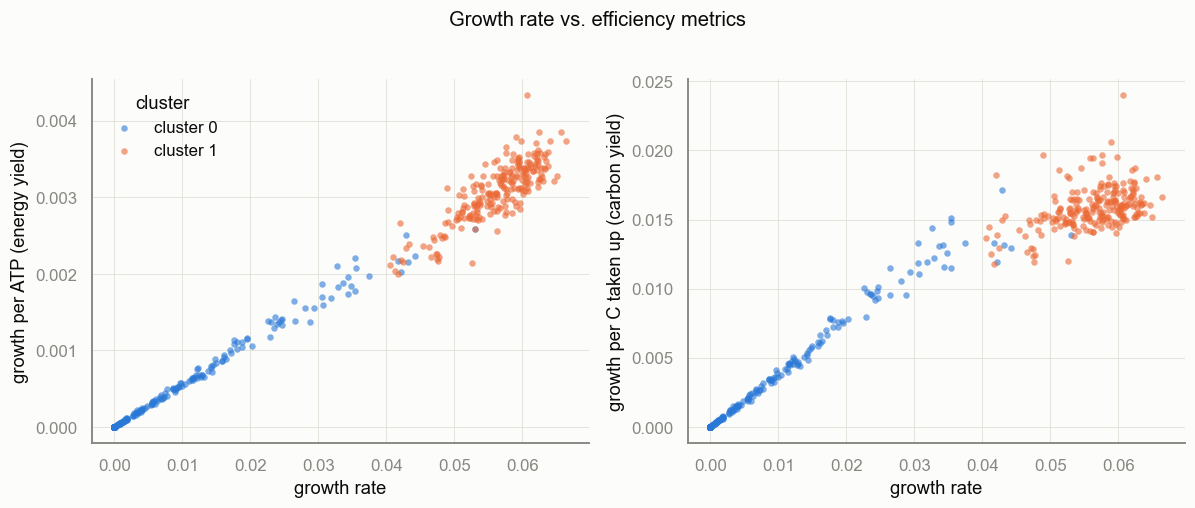

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, yvar, ylabel in zip(axes, ['energy_yield', 'carbon_yield'],
                            ['growth per ATP (energy yield)', 'growth per C taken up (carbon yield)']):
    for cl, color in CLUSTER_COLORS.items():
        sub = df[df['cluster'] == cl]
        ax.scatter(sub['growth'], sub[yvar], s=18, alpha=0.6, color=color, linewidth=0,
                   label=f'cluster {cl}')
    ax.set_xlabel('growth rate')
    ax.set_ylabel(ylabel)
axes[0].legend(frameon=False, title='cluster')
fig.suptitle('Growth rate vs. efficiency metrics', y=1.02)
plt.tight_layout()
plt.savefig('fig6_growth_vs_yield.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Organic carbon exchange (`ac`), by cluster

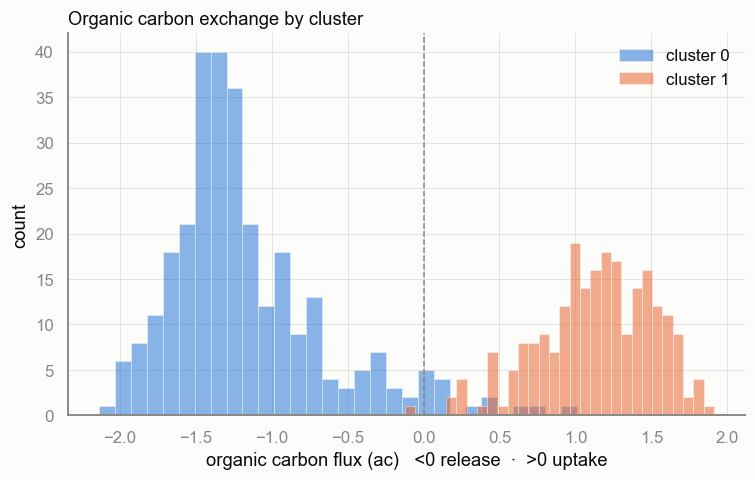

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for cl, color in CLUSTER_COLORS.items():
    sub = df[df['cluster'] == cl]
    ax.hist(sub['ac'], bins=30, alpha=0.55, color=color, label=f'cluster {cl}',
            edgecolor=SURFACE, linewidth=0.5)
ax.axvline(0, color=MUTED, linewidth=1, linestyle='--')
ax.set_xlabel('organic carbon flux (ac)   <0 release  ·  >0 uptake')
ax.set_ylabel('count')
ax.legend(frameon=False)
ax.set_title('Organic carbon exchange by cluster', loc='left')
plt.tight_layout()
plt.savefig('fig7_ac_hist.png', dpi=150, bbox_inches='tight')
plt.show()

## Summary table

In [11]:
summary_vars = DERIVED_VARS + ['growth']
summary = df.groupby('cluster')[summary_vars].agg(['mean', 'median', 'std']).round(4)
summary

ATP_total                  carbon_yield                 energy_yield  \
             mean   median     std         mean  median     std         mean   
cluster                                                                        
0         17.9122  17.8761  1.1159       0.0026  0.0004  0.0040       0.0004   
1         18.4071  18.3195  1.3159       0.0158  0.0157  0.0015       0.0031   

                        frac_from_fixation                 frac_from_organic  \
         median     std               mean  median     std              mean   
cluster                                                                        
0        0.0001  0.0006             0.9921  1.0000  0.0496            0.0079   
1        0.0031  0.0004             0.5153  0.4928  0.1343            0.4847   

                         growth                  
         median     std    mean  median     std  
cluster                                          
0        0.0000  0.0496  0.0070  0.0009  0.0108  
1        0.5072  0.1343  0.0562  0.0572  0.0053